# Telco Customer Churn: Exploratory Data Analysis

**Business question:** which customers leave, and what do they have in common?
All loading/cleaning lives in `src/data.py`; this notebook only explores.

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import data, config
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (7, 4)
raw = data.load_raw(); df = data.load_clean()
print(raw.shape, "->", df.shape)

(7043, 21) -> (7043, 20)


## 1. Data quality: missing values

In [2]:
blank = raw["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum(), "| their tenure values:", raw.loc[blank, "tenure"].unique())
print("Missing values after cleaning:", int(df.isna().sum().sum()))

Blank TotalCharges: 11 | their tenure values: [0]
Missing values after cleaning: 0


**Insight:** `TotalCharges` is stored as text and has 11 blank strings. All 11 customers have `tenure == 0`
(brand new, not billed yet), so the blank really means "nothing charged": we fill with 0 rather than dropping them or using a mean.
After cleaning there are no missing values.

## 2. Overall churn rate

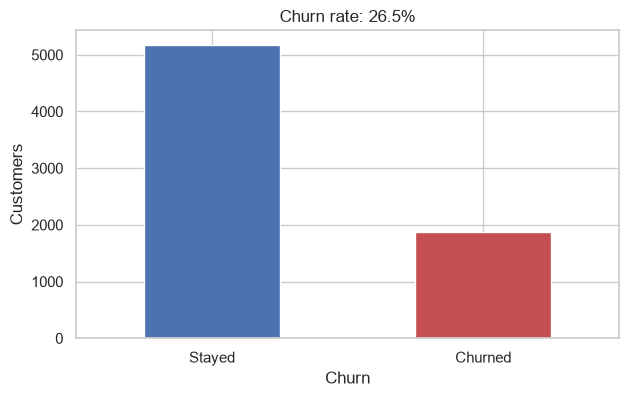

In [3]:
rate = df.Churn.mean()
ax = df.Churn.map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title(f"Churn rate: {rate:.1%}"); ax.set_ylabel("Customers"); plt.show()

**Insight:** 26.5% of customers churned (1,869 of 7,043). That is imbalanced: a model that always predicts "stays" is
73.5% accurate and catches zero churners. This is why we will not use accuracy later.

## 3. Churn by contract type

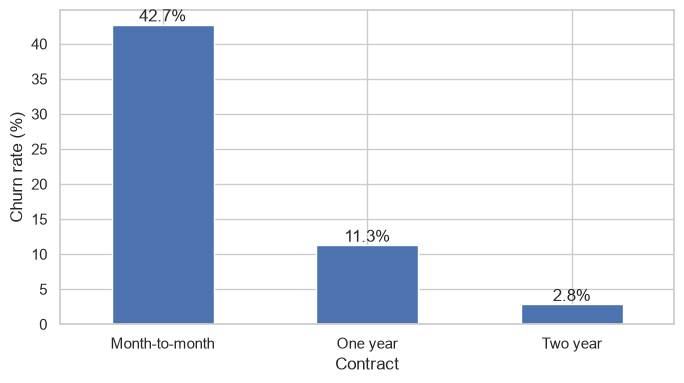

In [4]:
def churn_bar(col, order=None, rot=0):
    s = df.groupby(col).Churn.mean().mul(100)
    s = s.reindex(order) if order else s.sort_values()
    ax = s.plot.bar(color="#4C72B0", rot=rot); ax.set_ylabel("Churn rate (%)")
    for i, v in enumerate(s): ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    plt.tight_layout(); plt.show()
churn_bar("Contract", ["Month-to-month", "One year", "Two year"])

**Insight:** Contract is the strongest single signal. Month-to-month customers churn at 42.7%, one-year at 11.3% and
two-year at only 2.8%. Customers with no commitment can leave at any time; contracts lock them in. Moving people to longer contracts is the most obvious retention lever.

## 4. Churn by tenure

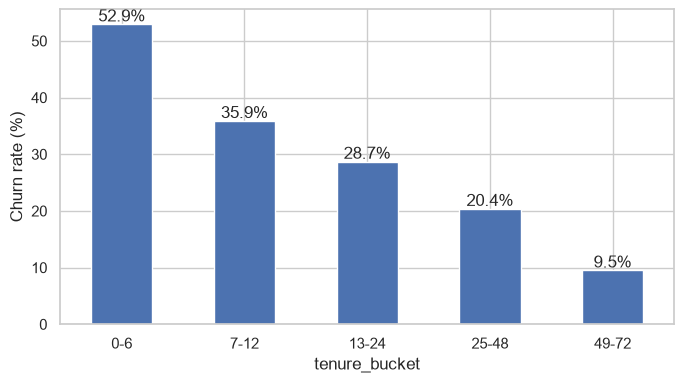

Median tenure (months): {0: 38.0, 1: 10.0}


In [5]:
df["tenure_bucket"] = pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
churn_bar("tenure_bucket", ["0-6", "7-12", "13-24", "25-48", "49-72"])
print("Median tenure (months):", df.groupby("Churn").tenure.median().to_dict())

**Insight:** Churn falls steadily with tenure: 52.9% in the first 6 months versus 9.5% after 4 years. Median tenure is 10 months for churners
and 38 for loyal customers. The first months are the danger zone, so onboarding and early-life offers matter most.

## 5. Churn by internet service

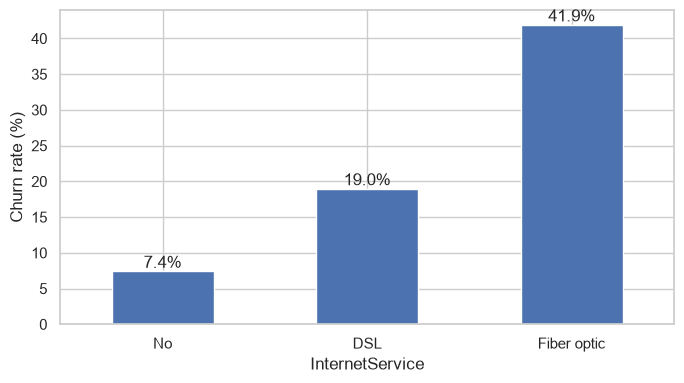

In [6]:
churn_bar("InternetService")

**Insight:** Fiber optic customers churn at 41.9%, more than double DSL (19.0%) and far above customers with no internet (7.4%).
Fiber is the premium, most expensive product, so this points to price sensitivity, service quality problems or competition, not that fiber itself is bad. We can't tell the cause from this data alone.

## 6. Churn by payment method

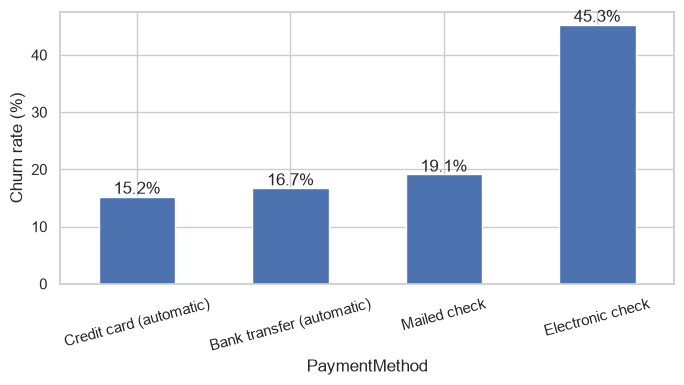

In [7]:
churn_bar("PaymentMethod", rot=15)

**Insight:** Electronic-check customers churn at 45.3%, versus 15-19% for every other method. Automatic payments (bank transfer, credit card)
are the lowest. Auto-pay probably reflects a more settled relationship, and also removes the monthly "do I still want this?" moment. It is a correlation, not proof that switching payment method would cut churn.

## 7. Churn by monthly charges

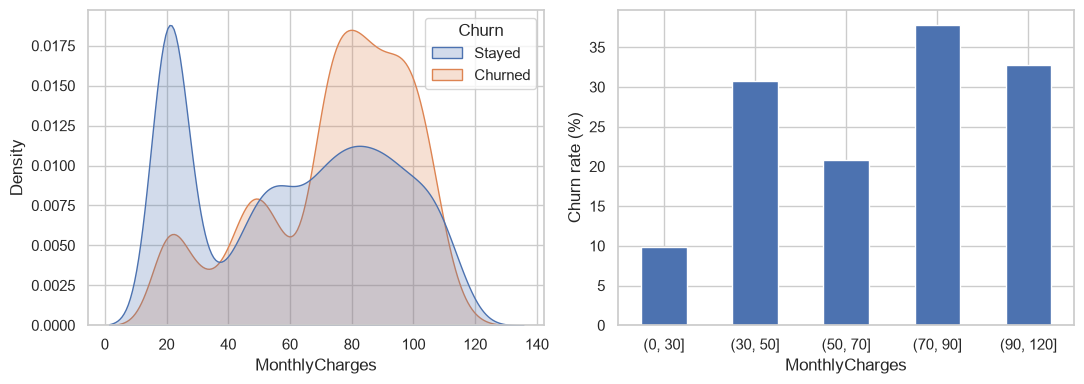

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.kdeplot(data=df, x="MonthlyCharges", hue=df.Churn.map({0: "Stayed", 1: "Churned"}), common_norm=False, fill=True, ax=ax[0])
b = pd.cut(df.MonthlyCharges, [0, 30, 50, 70, 90, 120])
(df.groupby(b, observed=True).Churn.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#4C72B0")
ax[1].set_ylabel("Churn rate (%)"); plt.tight_layout(); plt.show()

**Insight:** Churners skew to higher monthly bills (median $79.65 vs $64.43). Customers paying under $30 (mostly phone-only) churn at just 9.8%,
while the $70-90 band peaks at 37.8%. The relationship is not a clean line, because price is tangled up with service type and tenure, which is why we need a multivariable model.

## 8. Other signals: senior citizens and tech support

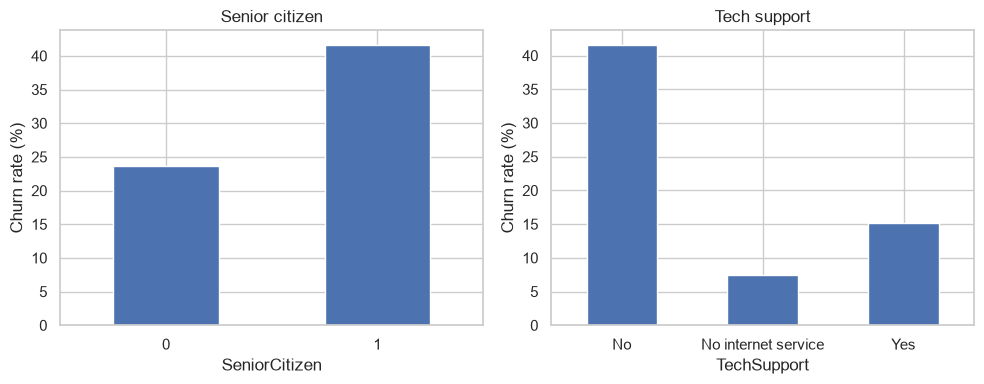

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
(df.groupby("SeniorCitizen").Churn.mean() * 100).plot.bar(ax=ax[0], rot=0, color="#4C72B0", title="Senior citizen")
(df.groupby("TechSupport").Churn.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#4C72B0", title="Tech support")
for a in ax: a.set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()

**Insight:** Seniors churn at 41.7% versus 23.6% for non-seniors. Customers with internet but *without* tech support churn at 41.6%, versus 15.2% for those with it.
Support services look protective, which motivates our engineered "has support services" feature.

## 9. Correlation view

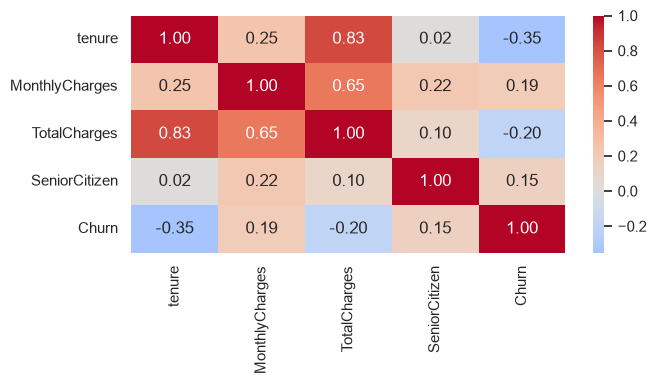

In [10]:
num = df[config.NUMERIC + ["SeniorCitizen", "Churn"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.tight_layout(); plt.show()

**Insight:** Tenure has the strongest linear relationship with churn (-0.35); monthly charges (+0.19) and senior status (+0.15) are weaker.
`TotalCharges` is highly correlated with tenure (it is roughly tenure x monthly charge), so it adds little independent information. That is fine for tree models but worth knowing for logistic regression.
Linear correlation also misses non-linear effects such as the contract and payment patterns above.

## Takeaways for modeling
1. Class imbalance (26.5%) means we must pick metrics and thresholds carefully.
2. Contract, tenure, internet service and payment method carry the most signal.
3. Engineered features worth trying: tenure buckets, number of services, average charge per month, a support-services flag and an auto-pay flag.